# CA1: Extra Experiment
# Neural Style Transfer for Artistic Image Generation


In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [21]:
import os

# Check if the images are already in the environment, otherwise prompt for upload
existing_files = [f for f in ['img2.jpeg', 'img1.jpeg'] if os.path.exists(f)]

if len(existing_files) >= 2:
    image_paths = existing_files
    print("Using existing files in workspace:", image_paths)
else:
    try:
        uploaded = files.upload()
        if uploaded:
            image_paths = list(uploaded.keys())
        else:
            image_paths = []
    except Exception as e:
        image_paths = []

if len(image_paths) < 2:
    raise ValueError("Upload or ensure two images are present: content image first (e.g., img2.jpeg), style image second (e.g., img1.jpeg).")

content_path, style_path = image_paths[0], image_paths[1]
print("Content:", content_path)
print("Style:", style_path)

Saving img2.jpeg to img2.jpeg
Saving img1.jpeg to img1 (1).jpeg
Content: img2.jpeg
Style: img1 (1).jpeg


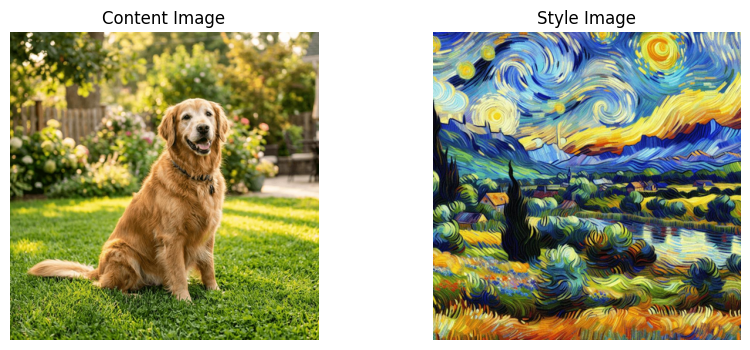

Content shape: (1, 400, 400, 3)
Style shape: (1, 400, 400, 3)


In [29]:
IMAGE_SIZE = 400

def load_image(path, max_dim=IMAGE_SIZE):
    image = Image.open(path).convert("RGB")
    width, height = image.size
    scale = max_dim / max(width, height)
    size = (int(width * scale), int(height * scale))
    image = image.resize(size, Image.Resampling.LANCZOS)
    image = np.array(image).astype("float32")
    return tf.convert_to_tensor(image[None, ...])

# Switched: content_image now loads style_path, style_image now loads content_path
content_image = load_image(style_path)
style_image = load_image(content_path)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(tf.cast(content_image[0], tf.uint8))
plt.title("Content Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(tf.cast(style_image[0], tf.uint8))
plt.title("Style Image")
plt.axis("off")
plt.show()

print("Content shape:", content_image.shape)
print("Style shape:", style_image.shape)

In [30]:
vgg = tf.keras.applications.VGG19(include_top=False, weights="imagenet")
vgg.trainable = False

content_layer = "block5_conv2"
style_layers = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1"
]
num_style_layers = len(style_layers)

outputs = [vgg.get_layer(name).output for name in style_layers]
outputs.append(vgg.get_layer(content_layer).output)
feature_extractor = tf.keras.Model(vgg.input, outputs)

print("VGG19 feature extractor ready.")

VGG19 feature extractor ready.


In [31]:
def preprocess_image(image):
    return tf.keras.applications.vgg19.preprocess_input(image)

def extract_features(image):
    outputs = feature_extractor(preprocess_image(image))
    return outputs[:num_style_layers], outputs[num_style_layers]

style_features, _ = extract_features(style_image)
_, content_features = extract_features(content_image)

print("Number of style feature maps:", len(style_features))
print("Content feature shape:", content_features.shape)

Number of style feature maps: 5
Content feature shape: (1, 25, 25, 512)


In [32]:
def gram_matrix(feature_map):
    channels = tf.shape(feature_map)[-1]
    features = tf.reshape(feature_map, (-1, channels))
    gram = tf.matmul(features, features, transpose_a=True)
    locations = tf.cast(tf.shape(feature_map)[1] * tf.shape(feature_map)[2], tf.float32)
    return gram / locations

def content_loss(target, generated):
    return tf.reduce_mean(tf.square(target - generated))

def style_loss(target_gram, generated_feature):
    generated_gram = gram_matrix(generated_feature)
    return tf.reduce_mean(tf.square(target_gram - generated_gram))

style_gram_targets = [gram_matrix(feature) for feature in style_features]
print("Loss functions and target Gram matrices ready.")

Loss functions and target Gram matrices ready.


In [33]:
STYLE_WEIGHT = 1e-2
CONTENT_WEIGHT = 1e4
TOTAL_STEPS = 300
LEARNING_RATE = 2.0

style_weight_per_layer = 1.0 / num_style_layers
generated_image = tf.Variable(content_image)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=0.99,
    epsilon=1e-1
)

In [34]:
@tf.function()
def compute_loss_and_gradients(image):
    with tf.GradientTape() as tape:
        generated_styles, generated_content = extract_features(image)

        c_loss = content_loss(content_features, generated_content)
        s_loss = tf.constant(0.0)

        for generated_feature, target_gram in zip(generated_styles, style_gram_targets):
            s_loss += style_weight_per_layer * style_loss(target_gram, generated_feature)

        total_loss = CONTENT_WEIGHT * c_loss + STYLE_WEIGHT * s_loss

    gradients = tape.gradient(total_loss, image)
    return total_loss, c_loss, s_loss, gradients

loss_history = []

for step in range(TOTAL_STEPS):
    total, c_loss, s_loss, gradients = compute_loss_and_gradients(generated_image)
    optimizer.apply_gradients([(gradients, generated_image)])
    generated_image.assign(tf.clip_by_value(generated_image, 0.0, 255.0))
    loss_history.append(float(total.numpy()))

    if (step + 1) % 50 == 0:
        print(f"Step {step+1}/{TOTAL_STEPS} | Total: {total.numpy():.4f} | "
              f"Content: {c_loss.numpy():.4f} | Style: {s_loss.numpy():.4f}")

Step 50/300 | Total: 71360864.0000 | Content: 2718.6211 | Style: 4417465856.0000
Step 100/300 | Total: 45626176.0000 | Content: 2070.2151 | Style: 2492402432.0000
Step 150/300 | Total: 33536188.0000 | Content: 1697.2065 | Style: 1656412288.0000
Step 200/300 | Total: 26557444.0000 | Content: 1432.5079 | Style: 1223236480.0000
Step 250/300 | Total: 22053636.0000 | Content: 1236.0424 | Style: 969321280.0000
Step 300/300 | Total: 18933008.0000 | Content: 1090.5743 | Style: 802726592.0000


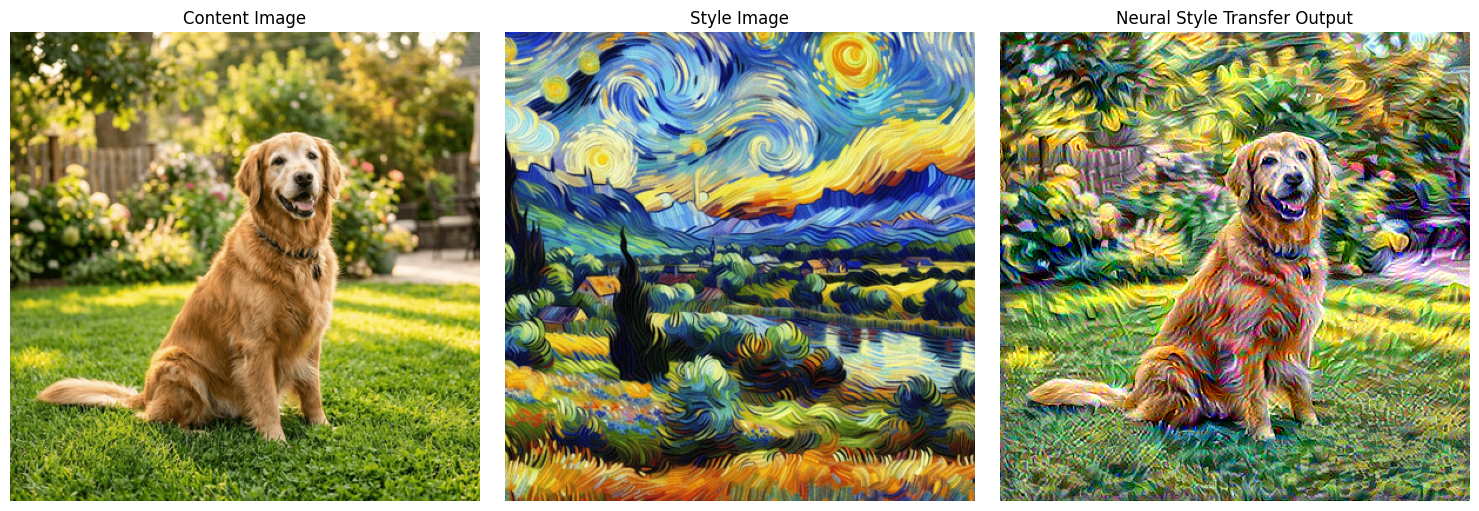

In [35]:
result = tf.cast(tf.clip_by_value(generated_image[0], 0, 255), tf.uint8).numpy()

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(tf.cast(content_image[0], tf.uint8))
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tf.cast(style_image[0], tf.uint8))
plt.title("Style Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title("Neural Style Transfer Output")
plt.axis("off")
plt.tight_layout()
plt.show()

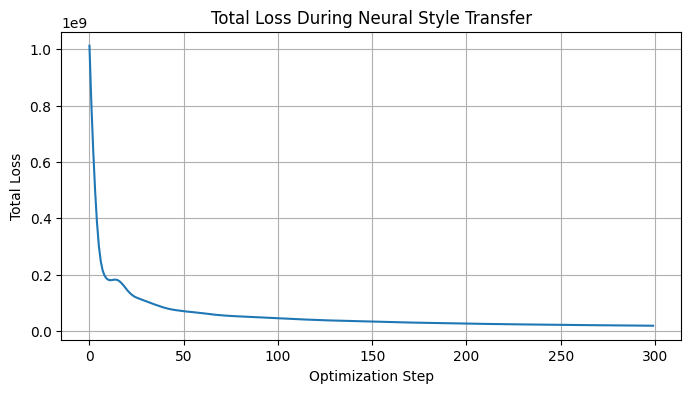

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: neural_style_transfer_output.png


In [36]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Total Loss During Neural Style Transfer")
plt.xlabel("Optimization Step")
plt.ylabel("Total Loss")
plt.grid(True)
plt.show()

output_path = "neural_style_transfer_output.png"
Image.fromarray(result).save(output_path)
files.download(output_path)
print("Saved:", output_path)